In [1]:
#!kaggle competitions download -c ai-generated-text-detection-hw3-ucu-ai-2026

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, entropy

In [3]:
df = pd.read_csv('../ai-generated-text-detection-hw3-ucu-ai-2026/train.csv')

In [4]:
df.head(10)

,id,text,lang,domain,label
0,e7adad,Diego's Demons Return: Is the Football Legend ...,en-EN,cnn_news,ai
1,3bab63,Herr Präsident! Meine Damen und Herren! Es wir...,de-DE,bundestag,human
2,4e6c1f,Frau Präsidentin! Liebe Kolleginnen und Kolleg...,de-DE,bundestag,human
3,f92d07,[12/17/2002 9:40:16 PM | + racheal] shagging. ...,en-EN,blog_authorship_corpus,human
4,6162f5,"IN THE COURT OF CASE NO. , Plaintiffs, v. , De...",en-EN,euro_court_cases,ai
5,77afe1,If he will make a statement on his plans for t...,en-EN,house_of_commons,human
6,a6f4c8,Personally i agree with the principals decisio...,en-EN,student_essays,human
7,b730ee,Sehr geehrte Frau Präsidentin! Liebe Kolleginn...,de-DE,bundestag,fusion
8,07ccae,"Output Text (58 words ""Hey CF Community! : I'm...",en-EN,blog_authorship_corpus,ai
9,3c2370,TSA Controversy: A Personal Space Violation at...,en-EN,cnn_news,ai


In [5]:
df.sample(10)

,id,text,lang,domain,label
263427,906eec,Is There Really a Face on Mars? Let's Talk Abo...,en-EN,student_essays,ai
72159,516ec2,By . Associated Press . You promise 'in sickne...,en-EN,cnn_news,fusion
218719,977874,6. On 13 April 2006 the Vlasotince Municipal C...,en-EN,euro_court_cases,fusion
267760,97a664,"Welcome back, mamas! We're officially in doubl...",en-EN,blog_authorship_corpus,ai
47180,d7b67f,Proposed Research and Development Tax Credit f...,en-EN,house_of_commons,ai
190763,485766,"RIYADH, Saudi Arabia (CNN) President Obama, on...",en-EN,cnn_news,fusion
124898,c6dcfb,"Mr. Speaker, I rise today with grave concerns ...",en-EN,house_of_commons,ai
165127,f422ea,"Sehr geehrte Damen und Herren, die Frage nach ...",de-DE,bundestag,ai
151177,69d41d,Section III: Relationship Between Zero-Tempera...,en-EN,arxiv_papers,ai
195618,ca7455,"4. The applicant, a Ukrainian national, was bo...",en-EN,euro_court_cases,human


In [6]:
df.shape

(272352, 5)

In [7]:
print(df.isna().sum())
print(df.duplicated().sum())

id        0
text      0
lang      0
domain    0
label     0
dtype: int64
0


<Axes: >

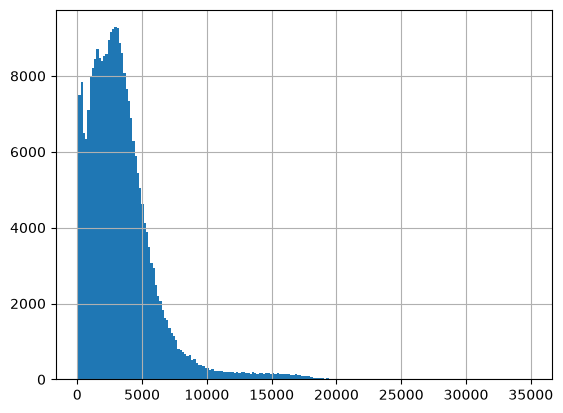

In [8]:
df['text'].str.len().hist(bins=200)

In [9]:
min_len = df['text'].str.len().min()
max_len = df['text'].str.len().max()
print(f"{min_len=}\n{max_len=}")

min_len=np.int64(76)
max_len=np.int64(34876)


In [13]:
ct = pd.crosstab(df["lang"], df["domain"], margins=True, margins_name="TOTAL")
print(ct.to_string())

domain  arxiv_papers  blog_authorship_corpus  bundestag  cnn_news  euro_court_cases  gutenberg  house_of_commons  student_essays   TOTAL
lang                                                                                                                                    
de-DE              0                       0      52343         0                 0        428                 0               0   52771
en-EN          14290                   40547          0     44285             27578       6916             31859           54106  219581
TOTAL          14290                   40547      52343     44285             27578       7344             31859           54106  272352


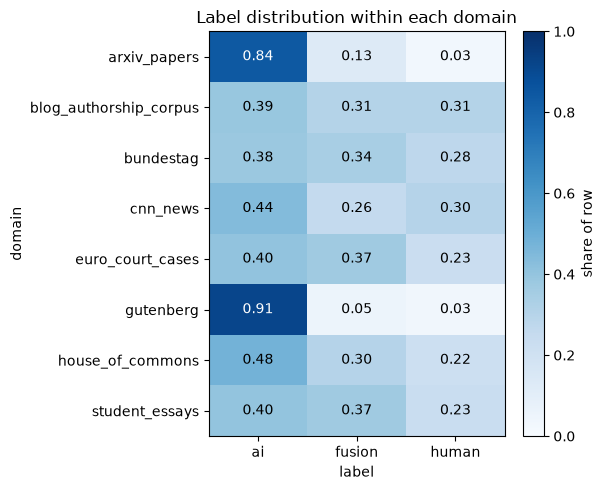

In [12]:
ct = pd.crosstab(df["domain"], df["label"], normalize="index")

fig, ax = plt.subplots(figsize=(6, 0.5 * len(ct) + 1))
im = ax.imshow(ct.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")

ax.set_xticks(range(ct.shape[1]), ct.columns)
ax.set_yticks(range(ct.shape[0]), ct.index)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        v = ct.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                color="white" if v > 0.5 else "black")

fig.colorbar(im, ax=ax, label="share of row")
ax.set_xlabel("label"); ax.set_ylabel("domain")
ax.set_title("Label distribution within each domain")
plt.tight_layout(); plt.show()

In [14]:
print(pd.crosstab(df["lang"], df["label"], margins=True, margins_name="TOTAL").to_string(), "\n")

label      ai  fusion  human   TOTAL
lang                                
de-DE   20337   17924  14510   52771
en-EN  101603   65758  52220  219581
TOTAL  121940   83682  66730  272352 



In [ ]:
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score

# ---------------- Config ----------------
SAMPLE       = 30_000   # None = full dataset (~272k texts; spaCy will take a long time)
MAX_CHARS    = 5_000    # truncate long texts to speed up spaCy
USE_LEMMA    = False    # AI detection relies on style; lemmas erase some of it
REMOVE_STOP  = False    # stopwords and punctuation are strong style signals, keep them
N_PROCESS    = 1        # >1 is faster but can hang in Jupyter on macOS/Windows
RANDOM_STATE = 42

data = df.sample(n=SAMPLE, random_state=RANDOM_STATE) if SAMPLE else df
data = data.copy()

# ---------------- spaCy tokenization (one model per language) ----------------
nlps = {
    "en-EN": spacy.load("en_core_web_sm", disable=["parser", "ner"]),
    "de-DE": spacy.load("de_core_news_sm", disable=["parser", "ner"]),
}

def tokenize(doc):
    toks = []
    for t in doc:
        if t.is_space or (REMOVE_STOP and (t.is_stop or t.is_punct)):
            continue
        toks.append((t.lemma_ if USE_LEMMA else t.text).lower())
    return toks

tokens = {}
for lang, nlp in nlps.items():
    sub = data[data["lang"] == lang]
    texts = sub["text"].astype(str).str[:MAX_CHARS].tolist()
    for idx, doc in zip(sub.index, nlp.pipe(texts, batch_size=256, n_process=N_PROCESS)):
        tokens[idx] = tokenize(doc)
    print(f"{lang}: tokenized {len(sub)} texts")

data["tokens"] = data.index.map(tokens)
data = data[data["tokens"].notna()]  # drops rows whose lang has no spaCy model

# ---------------- Split (stratified on domain + label) ----------------
strata = data["domain"] + "_" + data["label"]
train_idx, test_idx = train_test_split(
    data.index, test_size=0.2, random_state=RANDOM_STATE, stratify=strata
)

# ---------------- TF-IDF on pre-tokenized input ----------------
identity = lambda x: x
vec = TfidfVectorizer(
    tokenizer=identity, preprocessor=identity, lowercase=False, token_pattern=None,
    ngram_range=(1, 2), min_df=5, max_features=200_000, sublinear_tf=True,
)
X_train = vec.fit_transform(data.loc[train_idx, "tokens"])
X_test  = vec.transform(data.loc[test_idx, "tokens"])
y_train = data.loc[train_idx, "label"]
y_test  = data.loc[test_idx, "label"]
print("TF-IDF shape:", X_train.shape)

# ---------------- Classifier ----------------
clf = LogisticRegression(max_iter=2000, C=4.0, class_weight="balanced")
clf.fit(X_train, y_train)
pred = clf.predict(X_test)

print("\n=== Overall ===")
print(classification_report(y_test, pred, digits=3))

# ---------------- Per-domain accuracy vs majority-class baseline ----------------
test = data.loc[test_idx, ["domain", "lang", "label"]].assign(pred=pred)
rows = []
for d, g in test.groupby("domain"):
    rows.append({
        "domain": d,
        "n": len(g),
        "accuracy": accuracy_score(g["label"], g["pred"]),
        "majority_baseline": g["label"].value_counts(normalize=True).iloc[0],
    })
per_domain = pd.DataFrame(rows)
per_domain["gain_over_baseline"] = per_domain["accuracy"] - per_domain["majority_baseline"]
print("=== Per domain ===")
print(per_domain.round(3).sort_values("gain_over_baseline").to_string(index=False))

# ---------------- Top features per class ----------------
feat = vec.get_feature_names_out()
classes = clf.classes_
coefs = clf.coef_ if len(classes) > 2 else np.vstack([-clf.coef_[0], clf.coef_[0]])
for c, w in zip(classes, coefs):
    top = np.argsort(w)[-15:][::-1]
    print(f"\nTop features for '{c}': {', '.join(feat[top])}")

OSError: [E050] Can't find model 'en_core_web_sm'. It doesn't seem to be a Python package or a valid path to a data directory.